# 2.2 Exploratory analysis

This notebook belongs to step 2.2 of the extension, written up in `docs/report.md`, section 2.2. It reads the cleaned table from step 2.1.
A full run takes under a minute. Plots use the 111-day window. The 12 missing RTM values are filled by straight-line interpolation in the memory and
decomposition plots only.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, pacf

ROOT = Path("..").resolve()
FIG = ROOT / "docs" / "figures"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
c = pd.read_parquet(ROOT / "data" / "interim" / "clean.parquet")
c["weekday"] = c["date"].dt.day_of_week
c["weekend"] = c["weekday"] >= 5
c["spread"] = c["rtm_price"] - c["dam_price"]
c["month"] = c["date"].dt.strftime("%Y-%m")
print(
    len(c),
    "rows;",
    c["weekend"].groupby(c["date"]).first().sum(),
    "weekend days of",
    c["date"].nunique(),
)

10656 rows; 32 weekend days of 111


The window has 32 weekend days out of 111.

weekday RTM: lowest block 16 2083.0 | highest block 74 4144.0


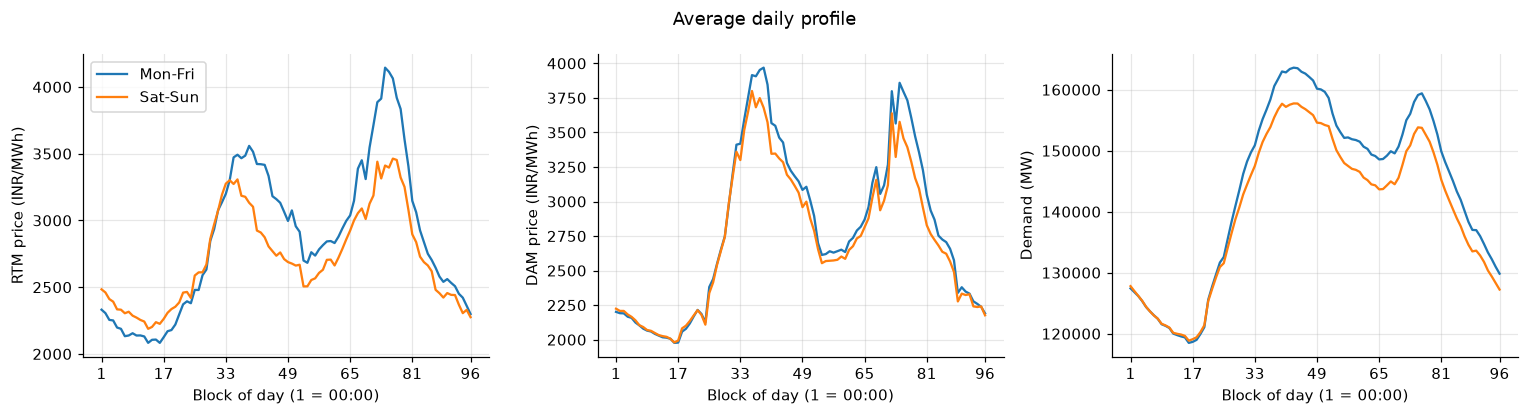

In [2]:
# Average day: RTM and DAM price by block, weekdays vs weekends
prof = c.groupby(["weekend", "block"])[["rtm_price", "dam_price", "demand"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for ax, col, label in zip(
    axes,
    ["rtm_price", "dam_price", "demand"],
    ["RTM price (INR/MWh)", "DAM price (INR/MWh)", "Demand (MW)"],
    strict=True,
):
    for weekend, name in [(False, "Mon-Fri"), (True, "Sat-Sun")]:
        ax.plot(prof.loc[weekend].index, prof.loc[weekend][col], label=name)
    ax.set_xlabel("Block of day (1 = 00:00)")
    ax.set_ylabel(label)
    ax.set_xticks([1, 17, 33, 49, 65, 81, 96])
axes[0].legend()
fig.suptitle("Average daily profile")
fig.tight_layout()
fig.savefig(FIG / "02_daily_profile.png")
peak = prof.loc[False]["rtm_price"]
print(
    "weekday RTM: lowest block",
    int(peak.idxmin()),
    round(peak.min(), 0),
    "| highest block",
    int(peak.idxmax()),
    round(peak.max(), 0),
)

Prices have two peaks a day: late morning and early evening. On weekdays the lowest average RTM price is in block 16 (2083 INR/MWh)
and the highest in block 74 (4144). The weekend evening peak is clearly lower than the weekday one.

In [3]:
# Weekday effect and month-to-month level
dow = c.groupby("weekday")[["rtm_price", "dam_price", "demand"]].mean().round(0)
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(dow.to_string())
month = (
    c.groupby("month")
    .agg(
        rtm_mean=("rtm_price", "mean"),
        rtm_std=("rtm_price", "std"),
        dam_mean=("dam_price", "mean"),
        dam_std=("dam_price", "std"),
        spread_mean=("spread", "mean"),
    )
    .round(0)
)
print()
print(month.to_string())

     rtm_price  dam_price    demand
Mon     2837.0     2822.0  142519.0
Tue     2963.0     2867.0  143707.0
Wed     2784.0     2742.0  144735.0
Thu     2836.0     2800.0  144044.0
Fri     2912.0     2768.0  143553.0
Sat     2891.0     2788.0  142587.0
Sun     2550.0     2649.0  138194.0

         rtm_mean  rtm_std  dam_mean  dam_std  spread_mean
month                                                     
2020-10    2691.0    664.0    2659.0    516.0         32.0
2020-11    2748.0    662.0    2652.0    536.0         95.0
2020-12    2938.0    924.0    2828.0    799.0        110.0
2021-01    2981.0   1030.0    3083.0   1134.0       -103.0


Only Sunday is a low day. Its mean RTM price is 2550, while Saturday (2891) is close to the weekdays (2784 to 2963). My first notebook flagged Saturday
and Sunday together. That hides this difference.

Levels also move over the months. The mean RTM price rises from 2691 in October to 2981 in January, and its standard deviation from 664 to 1030.
In January the RTM price is on average below the DAM price (spread -103), while in the other months it is above.

spread mean 48.0 | median 83.2 | std 593.8 | RTM above DAM in 59.0 % of blocks
correlation RTM vs DAM (same block): 0.721


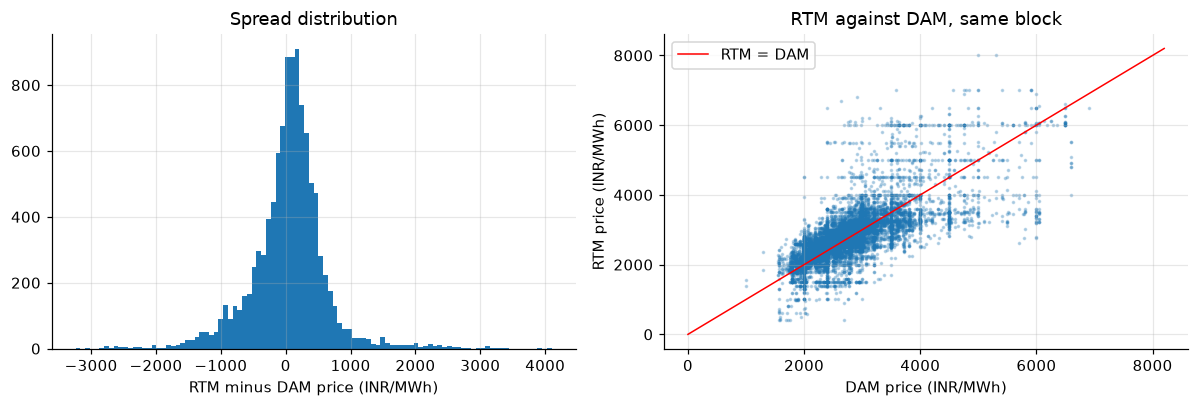

In [4]:
# RTM minus DAM price in the same block
s = c["spread"].dropna()
print(
    "spread mean",
    round(s.mean(), 1),
    "| median",
    round(s.median(), 1),
    "| std",
    round(s.std(), 1),
    "| RTM above DAM in",
    round((s > 0).mean() * 100, 1),
    "% of blocks",
)
print("correlation RTM vs DAM (same block):", round(c["rtm_price"].corr(c["dam_price"]), 3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(s, bins=100)
axes[0].set_xlabel("RTM minus DAM price (INR/MWh)")
axes[0].set_title("Spread distribution")
axes[1].scatter(c["dam_price"], c["rtm_price"], s=2, alpha=0.25)
lim = [0, 8200]
axes[1].plot(lim, lim, color="red", lw=1, label="RTM = DAM")
axes[1].set_xlabel("DAM price (INR/MWh)")
axes[1].set_ylabel("RTM price (INR/MWh)")
axes[1].set_title("RTM against DAM, same block")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "02_rtm_vs_dam.png")

RTM is above DAM in 59.0 percent of blocks. The mean gap is 48 INR/MWh, the median 83, and the standard deviation 594, so the gap is small on average and large in single blocks.
The two prices move together (correlation 0.721) but not closely. The scatter shows RTM prices sitting on horizontal lines at round values such as 6000.

 lag meaning   acf
   1  15 min 0.936
   2  30 min 0.884
   4     1 h 0.777
   8     2 h 0.561
  96   1 day 0.660
 192  2 days 0.537
 672  1 week 0.409


largest PACF beyond lag 1: 0.08 | PACF at lag 1: 0.936
PACF lags above the 95 percent band among the first 96: [1, 2, 3, 4, 5, 6, 8, 12, 13, 17, 21, 22, 23, 38, 40, 47, 50, 51, 53, 59, 62, 68, 71, 72, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94]


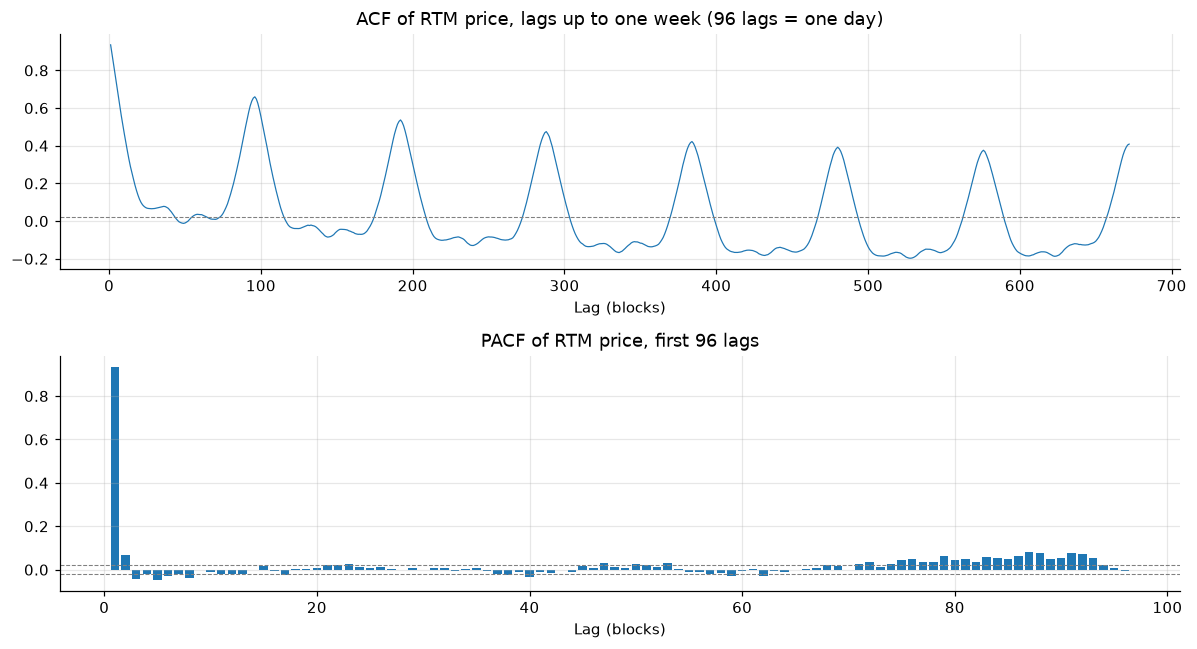

In [5]:
# Memory in the series. The 12 missing RTM values are filled by straight-line interpolation for this plot only.
y = c["rtm_price"].interpolate(limit_direction="both").to_numpy()
nlags = 96 * 7
ac = acf(y, nlags=nlags)
pc = pacf(y, nlags=96 * 2)
table = pd.DataFrame({"lag": [1, 2, 4, 8, 96, 192, 672]})
table["meaning"] = ["15 min", "30 min", "1 h", "2 h", "1 day", "2 days", "1 week"]
table["acf"] = [round(ac[k], 3) for k in table["lag"]]
print(table.to_string(index=False))
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(range(1, nlags + 1), ac[1:], lw=0.8)
axes[0].axhline(2 / np.sqrt(len(y)), color="gray", ls="--", lw=0.7)
axes[0].set_title("ACF of RTM price, lags up to one week (96 lags = one day)")
axes[0].set_xlabel("Lag (blocks)")
axes[1].bar(range(1, 97), pc[1:97], width=0.8)
axes[1].axhline(2 / np.sqrt(len(y)), color="gray", ls="--", lw=0.7)
axes[1].axhline(-2 / np.sqrt(len(y)), color="gray", ls="--", lw=0.7)
axes[1].set_title("PACF of RTM price, first 96 lags")
axes[1].set_xlabel("Lag (blocks)")
fig.tight_layout()
fig.savefig(FIG / "02_acf_pacf.png")
print(
    "largest PACF beyond lag 1:", round(max(abs(pc[2:97])), 3), "| PACF at lag 1:", round(pc[1], 3)
)
print(
    "PACF lags above the 95 percent band among the first 96:",
    [k for k in range(1, 97) if abs(pc[k]) > 2 / np.sqrt(len(y))],
)

Yesterday's price at the same time is a better guide than the price two hours ago. The autocorrelation (how strongly a value resembles the value some lags earlier)
is 0.936 at 15 minutes, 0.777 at one hour and 0.561 at two hours, then rises again to 0.660 at one day. It is still 0.409 at one week.
In the partial autocorrelation, which removes the effect of the lags in between, lag 1 is the only large value.

daily seasonal strength: 0.689 | trend strength: 0.454


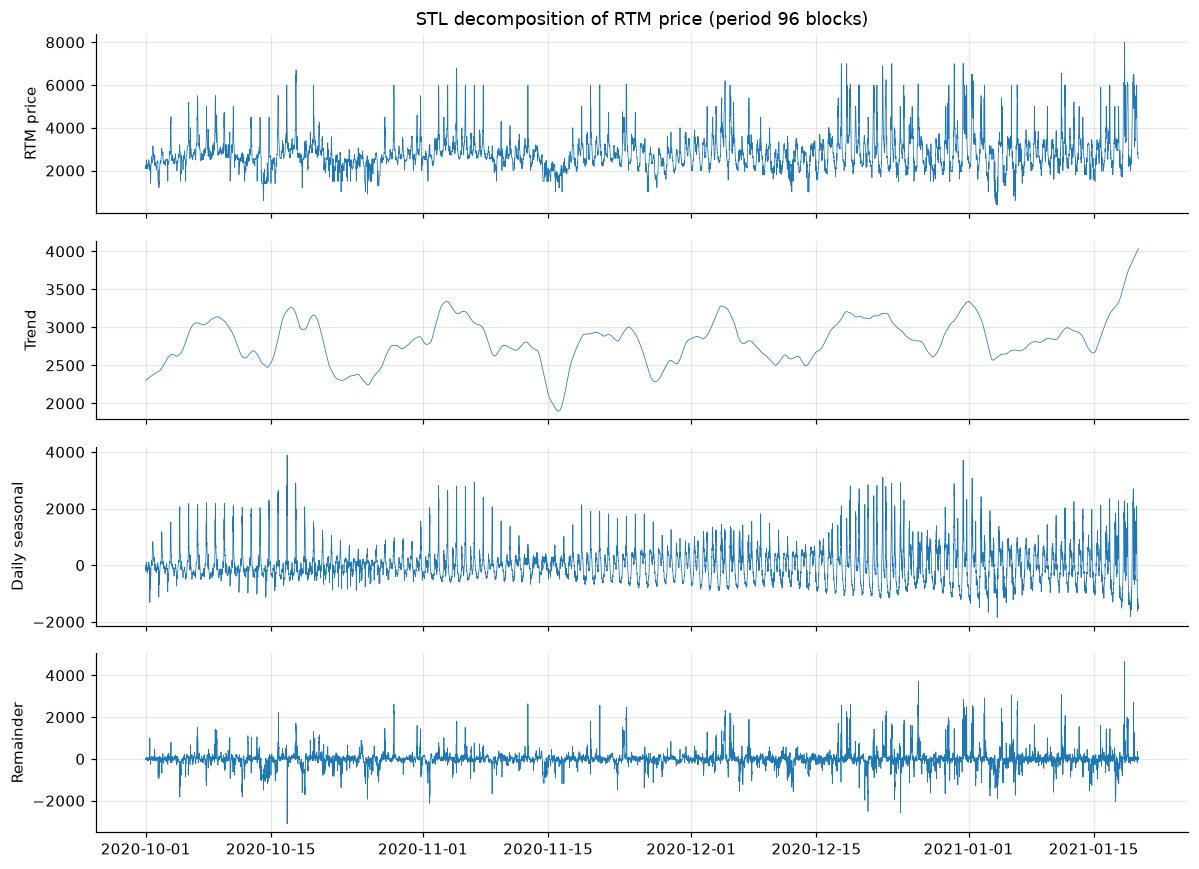

In [6]:
# Seasonal strength with STL (period = one day = 96 blocks), robust to spikes
series = pd.Series(y, index=c["timestamp"])
res = STL(series, period=96, robust=True).fit()


def strength(component: pd.Series, resid: pd.Series) -> float:
    return max(0.0, 1 - resid.var() / (component + resid).var())


print(
    "daily seasonal strength:",
    round(strength(res.seasonal, res.resid), 3),
    "| trend strength:",
    round(strength(res.trend, res.resid), 3),
)
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, part, name in zip(
    axes,
    [series, res.trend, res.seasonal, res.resid],
    ["RTM price", "Trend", "Daily seasonal", "Remainder"],
    strict=True,
):
    ax.plot(part, lw=0.5)
    ax.set_ylabel(name)
axes[0].set_title("STL decomposition of RTM price (period 96 blocks)")
fig.tight_layout()
fig.savefig(FIG / "02_stl.png")

A decomposition into trend, daily pattern and remainder (STL) gives a daily seasonal strength of 0.689 and a trend strength of 0.454 on a 0 to 1 scale.
So the daily shape explains a good part of the movement, and a slow drift matters as well.

mean daily std, first half: 528.0 | second half: 786.0
days with RTM maximum above 6000: 31 | first such day: 2020-10-16
19 Jan 2021: mean 3990.0 | std 1476.0 | rank of std (1 = highest of 111 days): 3 | rank of mean: 1


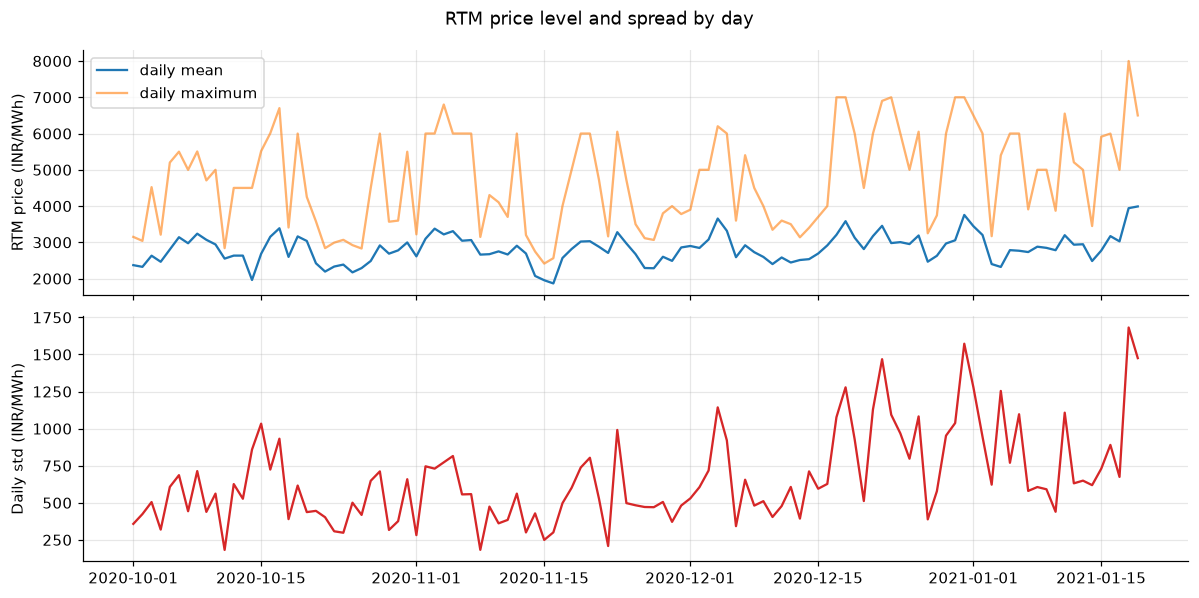

In [7]:
# Volatility over time
day = c.groupby("date")["rtm_price"].agg(["mean", "std", "max"])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(day.index, day["mean"], label="daily mean")
axes[0].plot(day.index, day["max"], label="daily maximum", alpha=0.6)
axes[0].set_ylabel("RTM price (INR/MWh)")
axes[0].legend()
axes[1].plot(day.index, day["std"], color="tab:red")
axes[1].set_ylabel("Daily std (INR/MWh)")
fig.suptitle("RTM price level and spread by day")
fig.tight_layout()
fig.savefig(FIG / "02_volatility.png")
half = len(day) // 2
print(
    "mean daily std, first half:",
    round(day["std"].iloc[:half].mean(), 0),
    "| second half:",
    round(day["std"].iloc[half:].mean(), 0),
)
print(
    "days with RTM maximum above 6000:",
    int((day["max"] > 6000).sum()),
    "| first such day:",
    day.index[day["max"] > 6000][0].date(),
)
last = day.loc["2021-01-19"]
print(
    "19 Jan 2021: mean",
    round(last["mean"], 0),
    "| std",
    round(last["std"], 0),
    "| rank of std (1 = highest of",
    len(day),
    "days):",
    int(day["std"].rank(ascending=False)["2021-01-19"]),
    "| rank of mean:",
    int(day["mean"].rank(ascending=False)["2021-01-19"]),
)

Volatility grows. The mean daily standard deviation is 528 INR/MWh in the first half of the window and 786 in the second half.
There are 31 days with a maximum above 6000, and the first is 16 October.
The last day, 19 January 2021, is the one my first notebook used as its single test day. Its mean RTM price (3990) is the highest of the 111 days, and its daily standard deviation (1476) is the third highest. It is an unusually hard day, so one result on it says little about typical performance.

rows used: 8857 of 10656
corr(demand, RTM price): 0.688 | corr(demand, DAM price): 0.784


hours with the highest and lowest correlation: 9 0.69 / 22 0.24


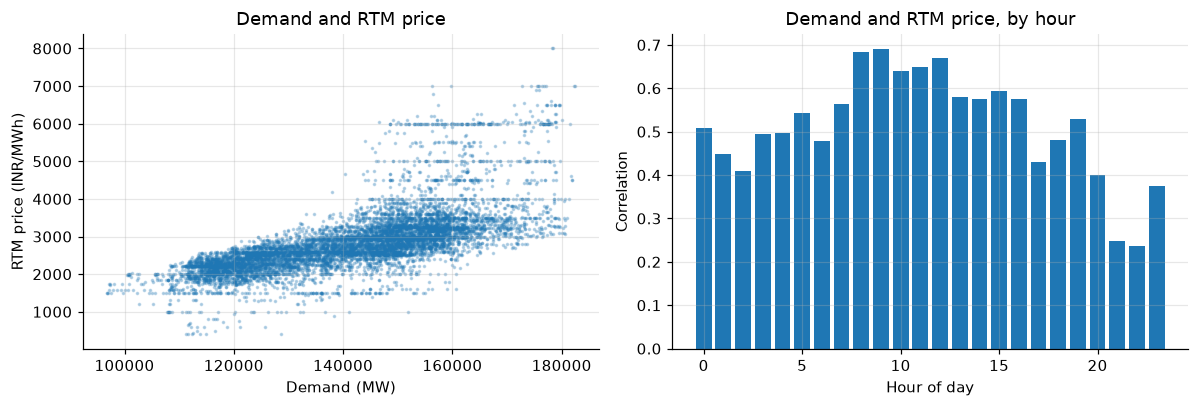

In [8]:
# Demand and price. The first 15 days and runs of repeated values are left out (see the audit notebook).
ok = c[(c["date"] >= "2020-10-16")].copy()
run_id = (ok["demand"].diff() != 0).cumsum()
ok = ok[ok.groupby(run_id)["demand"].transform("size") < 4]
print("rows used:", len(ok), "of", len(c))
print(
    "corr(demand, RTM price):",
    round(ok["demand"].corr(ok["rtm_price"]), 3),
    "| corr(demand, DAM price):",
    round(ok["demand"].corr(ok["dam_price"]), 3),
)
by_hour = (
    ok.assign(hour=(ok["block"] - 1) // 4)
    .groupby("hour")
    .apply(lambda g: g["demand"].corr(g["rtm_price"]), include_groups=False)
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(ok["demand"], ok["rtm_price"], s=2, alpha=0.25)
axes[0].set_xlabel("Demand (MW)")
axes[0].set_ylabel("RTM price (INR/MWh)")
axes[0].set_title("Demand and RTM price")
axes[1].bar(by_hour.index, by_hour.values)
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Correlation")
axes[1].set_title("Demand and RTM price, by hour")
fig.tight_layout()
fig.savefig(FIG / "02_demand_price.png")
print(
    "hours with the highest and lowest correlation:",
    int(by_hour.idxmax()),
    round(by_hour.max(), 2),
    "/",
    int(by_hour.idxmin()),
    round(by_hour.min(), 2),
)

I leave out the first 15 days and the repeated-value runs, which leaves 8857 of the 10656 rows. Demand is correlated with the RTM price at 0.688 and with the DAM price at 0.784.
By hour of day the correlation with the RTM price is strongest at hour 9 (0.69) and weakest at hour 22 (0.24).

In [9]:
# Spikes: where and when do the extreme RTM prices occur?
p = c["rtm_price"]
thr = p.mean() + 3 * p.std()
spikes = c[p > thr]
print(
    "threshold (mean + 3 std):",
    round(thr, 0),
    "| blocks above it:",
    len(spikes),
    "on",
    spikes["date"].nunique(),
    "days",
)
print(
    "by hour of day:",
    spikes.assign(hour=(spikes["block"] - 1) // 4)["hour"].value_counts().sort_index().to_dict(),
)
print("by month:", spikes["month"].value_counts().sort_index().to_dict())

threshold (mean + 3 std): 5292.0 | blocks above it: 268 on 42 days
by hour of day: {7: 3, 8: 19, 9: 42, 10: 31, 11: 14, 12: 7, 15: 1, 16: 8, 17: 34, 18: 68, 19: 40, 20: 1}
by month: {'2020-10': 30, '2020-11': 36, '2020-12': 106, '2021-01': 96}


There are 268 blocks above 5292 INR/MWh (mean plus three standard deviations), on 42 days. Most of them fall in hours 8 to 10 (92 blocks) and hours 17 to 19 (142 blocks).
December has 106 of them and January 96, although January has only 19 days in the data.

**What I understand.** The market has a clear daily shape, a Sunday dip, rising volatility and spikes in two daily windows. The DAM price of the same block is the single
most informative input I have, and yesterday's RTM price at the same block is informative too. A good model has to do more than copy either. The rising volatility also means that
a test period near the end of the window will be harder than one near the start. One test day, and especially 19 January, is not a fair test, so step 2.5 evaluates over many days.